# 🛒 Segmentación de clientes de Olist con RFM y Machine Learning clásico

**Especialización en Inteligencia Artificial · CUN · Aprendizaje Automático · ACA N° 1**
**Pilar:** Ventas  |  **Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Olist, 2018)

---

### 🎯 Objetivo general
Segmentar a los clientes de un marketplace brasileño a partir de su comportamiento de compra (**Recencia, Frecuencia y Valor Monetario**) usando tres algoritmos clásicos de clustering, y desplegar los resultados en una app interactiva de Streamlit.

### ❓ Pregunta orientadora
> ¿Cómo transformar los datos transaccionales de ventas en **segmentos de clientes accionables** mediante Machine Learning clásico y presentarlos en una interfaz accesible para usuarios de negocio?

### 🛠 Ruta metodológica
`1. EDA` → `2. Limpieza e integración (RFM)` → `3. Escalado` → `4. Modelado (K-Means · Jerárquico · DBSCAN)` → `5. Evaluación` → `6. Perfilamiento` → `7. Despliegue en Streamlit`

> 💡 *Nota de estudiante:* en este notebook cada decisión importante (por qué `customer_unique_id`, por qué `log1p`, por qué k=4, por qué esos `eps`) viene con evidencia calculada, no con "porque sí".

## 0. Configuración del entorno

In [1]:
import sys, textwrap, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Raíz del repo (el notebook vive en /notebooks) para poder importar el paquete `src`
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data_prep import (RAW_DIR, PROCESSED_PATH, load_raw, build_order_table, build_rfm,
                           add_profile_features)
from src.modeling import (SEED, FEATURES, MODEL_NAMES, prepare_features, fit_model, scan_k,
                          evaluate_clustering, compare_models, profile_segments, name_segments,
                          recommend_action)

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
def save_fig(name):                      # guarda la figura para el README / póster
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

print("Raíz del proyecto:", ROOT.name, "| Datos crudos en:", RAW_DIR.relative_to(ROOT))

Raíz del proyecto: olist-customer-segmentation | Datos crudos en: data/raw


## 1. Exploración inicial de los datos (EDA)

Olist publica un esquema relacional de 9 archivos. Primero inventariamos qué hay y qué tablas realmente necesitamos para construir RFM **a nivel cliente**.

In [2]:
FILES = {
    "olist_customers_dataset.csv":        "✅ Sí: vincula la orden con el cliente real",
    "olist_orders_dataset.csv":           "✅ Sí: fechas y estado de la orden (Recencia, Frecuencia)",
    "olist_order_payments_dataset.csv":   "✅ Sí: valor pagado (Monetario)",
    "olist_order_items_dataset.csv":       "✅ Perfilamiento: productos comprados",
    "olist_products_dataset.csv":         "✅ Perfilamiento: categoría del producto",
    "product_category_name_translation.csv": "✅ Perfilamiento: traducción PT→EN de categorías",
    "olist_order_reviews_dataset.csv":    "✅ Perfilamiento: satisfacción (reseñas)",
    "olist_sellers_dataset.csv":          "❌ No: describe vendedores, no clientes",
    "olist_geolocation_dataset.csv":      "❌ No: lat/lon por código postal (posible extensión futura)",
}
rows = []
for f, uso in FILES.items():
    d = pd.read_csv(RAW_DIR / f)
    rows.append({"archivo": f, "filas": len(d), "columnas": d.shape[1], "¿se usa?": uso})
pd.DataFrame(rows).set_index("archivo")

,filas,columnas,¿se usa?
archivo,,,
olist_customers_dataset.csv,99441,5,✅ Sí: vincula la orden con el cliente real
olist_orders_dataset.csv,99441,8,"✅ Sí: fechas y estado de la orden (Recencia, F..."
olist_order_payments_dataset.csv,103886,5,✅ Sí: valor pagado (Monetario)
olist_order_items_dataset.csv,112650,7,✅ Perfilamiento: productos comprados
olist_products_dataset.csv,32951,9,✅ Perfilamiento: categoría del producto
product_category_name_translation.csv,71,2,✅ Perfilamiento: traducción PT→EN de categorías
olist_order_reviews_dataset.csv,99224,7,✅ Perfilamiento: satisfacción (reseñas)
olist_sellers_dataset.csv,3095,4,"❌ No: describe vendedores, no clientes"
olist_geolocation_dataset.csv,1000163,5,❌ No: lat/lon por código postal (posible exten...


In [3]:
tables = load_raw(RAW_DIR)                      # solo las 7 tablas que usaremos
customers, orders, payments = tables["customers"], tables["orders"], tables["payments"]

# --- Hallazgo 1: customer_id NO identifica a una persona, customer_unique_id sí ---
print(f"Filas en customers:           {len(customers):,}")
print(f"customer_id únicos:           {customers['customer_id'].nunique():,}  (uno por ORDEN)")
print(f"customer_unique_id únicos:    {customers['customer_unique_id'].nunique():,}  (personas reales)")
print("\n=> Si usáramos customer_id, todos los clientes tendrían Frecuencia = 1. Usaremos customer_unique_id.")

Filas en customers:           99,441
customer_id únicos:           99,441  (uno por ORDEN)
customer_unique_id únicos:    96,096  (personas reales)

=> Si usáramos customer_id, todos los clientes tendrían Frecuencia = 1. Usaremos customer_unique_id.


Rango de fechas: 2016-09-04 a 2018-10-17
% de órdenes 'delivered': 97.0%


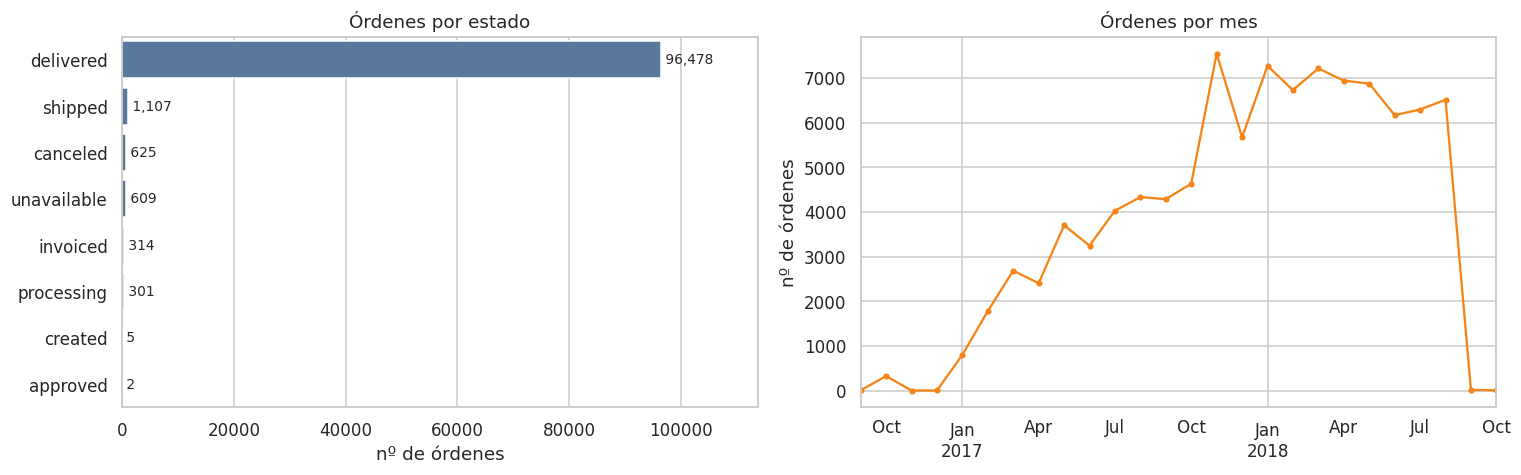

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Estado de las órdenes
status = orders["order_status"].value_counts()
sns.barplot(x=status.values, y=status.index, ax=ax[0], color="#4c78a8")
ax[0].set_title("Órdenes por estado"); ax[0].set_xlabel("nº de órdenes"); ax[0].set_ylabel("")
for i, v in enumerate(status.values):
    ax[0].text(v, i, f" {v:,}", va="center", fontsize=9)
ax[0].set_xlim(0, status.max() * 1.18)

# Evolución mensual
monthly = orders.set_index("order_purchase_timestamp").resample("MS").size()
monthly.plot(ax=ax[1], color="#f58518", marker="o", ms=3)
ax[1].set_title("Órdenes por mes"); ax[1].set_xlabel(""); ax[1].set_ylabel("nº de órdenes")
plt.tight_layout(); save_fig("01_eda_ordenes"); plt.show()

print(f"Rango de fechas: {orders['order_purchase_timestamp'].min():%Y-%m-%d} a {orders['order_purchase_timestamp'].max():%Y-%m-%d}")
print(f"% de órdenes 'delivered': {100*(orders['order_status']=='delivered').mean():.1f}%")

Pagos con valor <= 0: 9
Órdenes SIN registro de pago: 1
Órdenes con más de un pago (cuotas/vouchers): 2,961


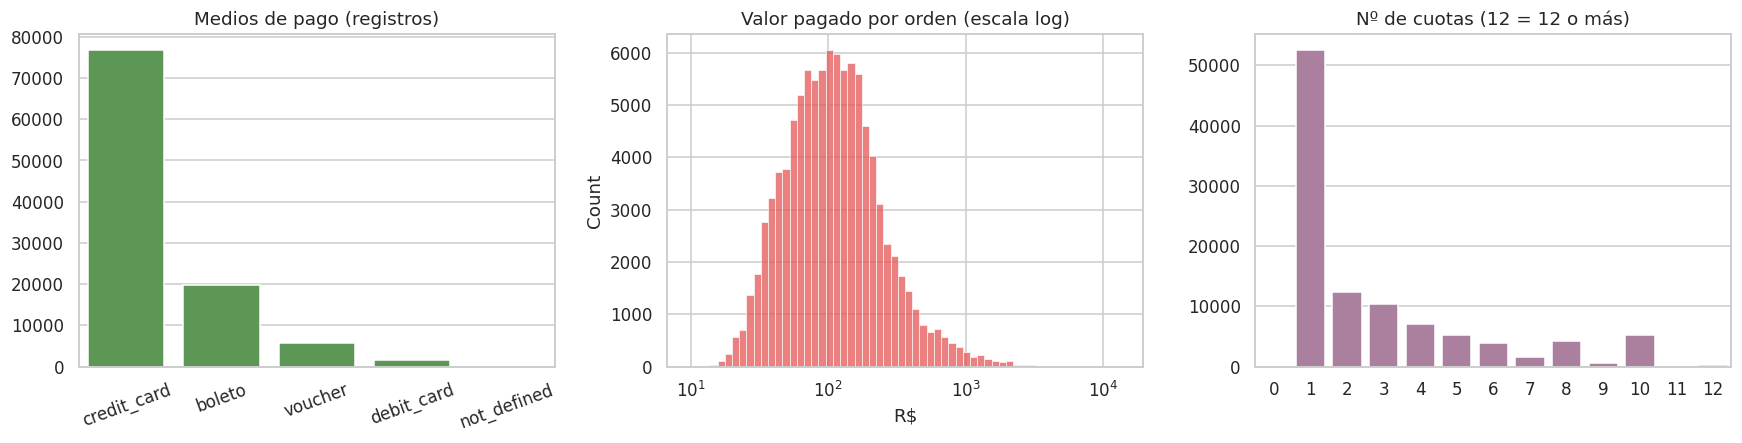

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

pt = payments["payment_type"].value_counts()
sns.barplot(x=pt.index, y=pt.values, ax=ax[0], color="#54a24b")
ax[0].set_title("Medios de pago (registros)"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=20)

pay_by_order = payments.groupby("order_id")["payment_value"].sum()
sns.histplot(pay_by_order[pay_by_order > 0], bins=60, log_scale=True, ax=ax[1], color="#e45756")
ax[1].set_title("Valor pagado por orden (escala log)"); ax[1].set_xlabel("R$")

inst = payments["payment_installments"].clip(upper=12).value_counts().sort_index()
sns.barplot(x=inst.index, y=inst.values, ax=ax[2], color="#b279a2")
ax[2].set_title("Nº de cuotas (12 = 12 o más)"); ax[2].set_xlabel("")
plt.tight_layout(); save_fig("02_eda_pagos"); plt.show()

print("Pagos con valor <= 0:", int((payments["payment_value"] <= 0).sum()))
print("Órdenes SIN registro de pago:", int((~orders["order_id"].isin(payments["order_id"])).sum()))
print("Órdenes con más de un pago (cuotas/vouchers):", f"{int((payments.groupby('order_id').size() > 1).sum()):,}")

In [6]:
# Valores nulos de las columnas de fechas de 'orders': ¿es un problema para nosotros?
nulls = orders.isna().mean().mul(100).rename("% nulos").to_frame()
nulls[nulls["% nulos"] > 0]

,% nulos
order_approved_at,0.161
order_delivered_carrier_date,1.793
order_delivered_customer_date,2.982


**Lectura del EDA**
- Hay ~99k órdenes entre sep-2016 y oct-2018: el volumen crece durante 2017, tiene un pico en **noviembre de 2017** (Black Friday) y se mantiene en una meseta durante 2018. Casi todas están `delivered` (~97%).
- ⚠️ La **caída abrupta después de ago-2018** no es una crisis del negocio sino el **corte del dataset**. Por eso la Recencia se mide respecto a la última fecha disponible y no respecto a la fecha de hoy.
- Los nulos en `order_approved_at` y fechas de entrega corresponden en su mayoría a órdenes aún no entregadas o canceladas; **no afectan** nuestro cálculo porque usamos `order_purchase_timestamp` (sin nulos) y filtramos por `delivered`.
- Una orden puede tener **varios pagos** (cuotas, vouchers), por lo que hay que **sumar por orden** antes de agregar por cliente (si no, se duplicaría la información).

## 2. Limpieza, integración y construcción del modelo RFM

Reglas de negocio (implementadas en `src/data_prep.py`):

| Decisión | Justificación |
|---|---|
| Unidad = `customer_unique_id` | `customer_id` cambia en cada orden |
| Solo órdenes `delivered` | Son ventas concretadas; canceladas/no disponibles no representan valor real |
| Monetario = Σ `payment_value` | Lo realmente pagado (incluye flete), agregado primero por orden |
| Recencia = fecha de referencia − última compra | Referencia = última fecha del dataset + 1 día |
| Se descartan órdenes sin pago o con valor ≤ 0 | No aportan información monetaria |

In [7]:
order_table = build_order_table(tables)           # 1 fila por orden válida
rfm = build_rfm(order_table)                      # 1 fila por cliente real
rfm.head()

[data_prep] órdenes entregadas: 96,478 -> válidas: 96,477


,customer_unique_id,frequency,monetary,avg_installments,customer_state,avg_delivery_days,avg_delay_days,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.900,8.000,SP,6.411,-4.133,111
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.190,1.000,SP,3.286,-4.248,114
2,0000f46a3911fa3c0805444483337064,1,86.220,8.000,SC,25.732,-1.390,537
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.620,4.000,PA,20.037,-11.109,321
4,0004aac84e0df4da2b147fca70cf8255,1,196.890,6.000,SP,13.141,-7.035,288


In [8]:
# Validaciones de calidad de datos
print("Clientes con RFM:", f"{len(rfm):,}")
print("customer_unique_id duplicados:", rfm["customer_unique_id"].duplicated().sum())
print("Nulos en R/F/M:", int(rfm[FEATURES].isna().sum().sum()))
print("Recencia mínima / máxima (días):", rfm["recency"].min(), "/", rfm["recency"].max())
print("Monetario mínimo / máximo (R$):", f"{rfm['monetary'].min():,.2f} / {rfm['monetary'].max():,.2f}")

freq = rfm["frequency"].value_counts().sort_index().to_frame("clientes")
freq["% del total"] = 100 * freq["clientes"] / freq["clientes"].sum()
freq.head(6)

Clientes con RFM: 93,357
customer_unique_id duplicados: 0
Nulos en R/F/M: 0
Recencia mínima / máxima (días): 0 / 695
Monetario mínimo / máximo (R$): 9.59 / 13,664.08


,clientes,% del total
frequency,,
1,90556,97.000
2,2573,2.756
3,181,0.194
4,28,0.030
5,9,0.010
6,5,0.005


> 🔎 **Hallazgo clave:** ~**97% de los clientes compró UNA sola vez**. Esto es una característica real del negocio (marketplace con baja recompra), no un error. Consecuencia técnica: la Frecuencia es casi constante, y los (pocos) clientes recurrentes serán "valores extremos" en esa dimensión. Lo tendremos en cuenta al interpretar los clusters.

Asimetría (skew) original: {'recency': 0.45, 'frequency': 11.1, 'monetary': 9.21}
Asimetría tras log1p:     {'recency': -1.25, 'frequency': 6.52, 'monetary': 0.53}


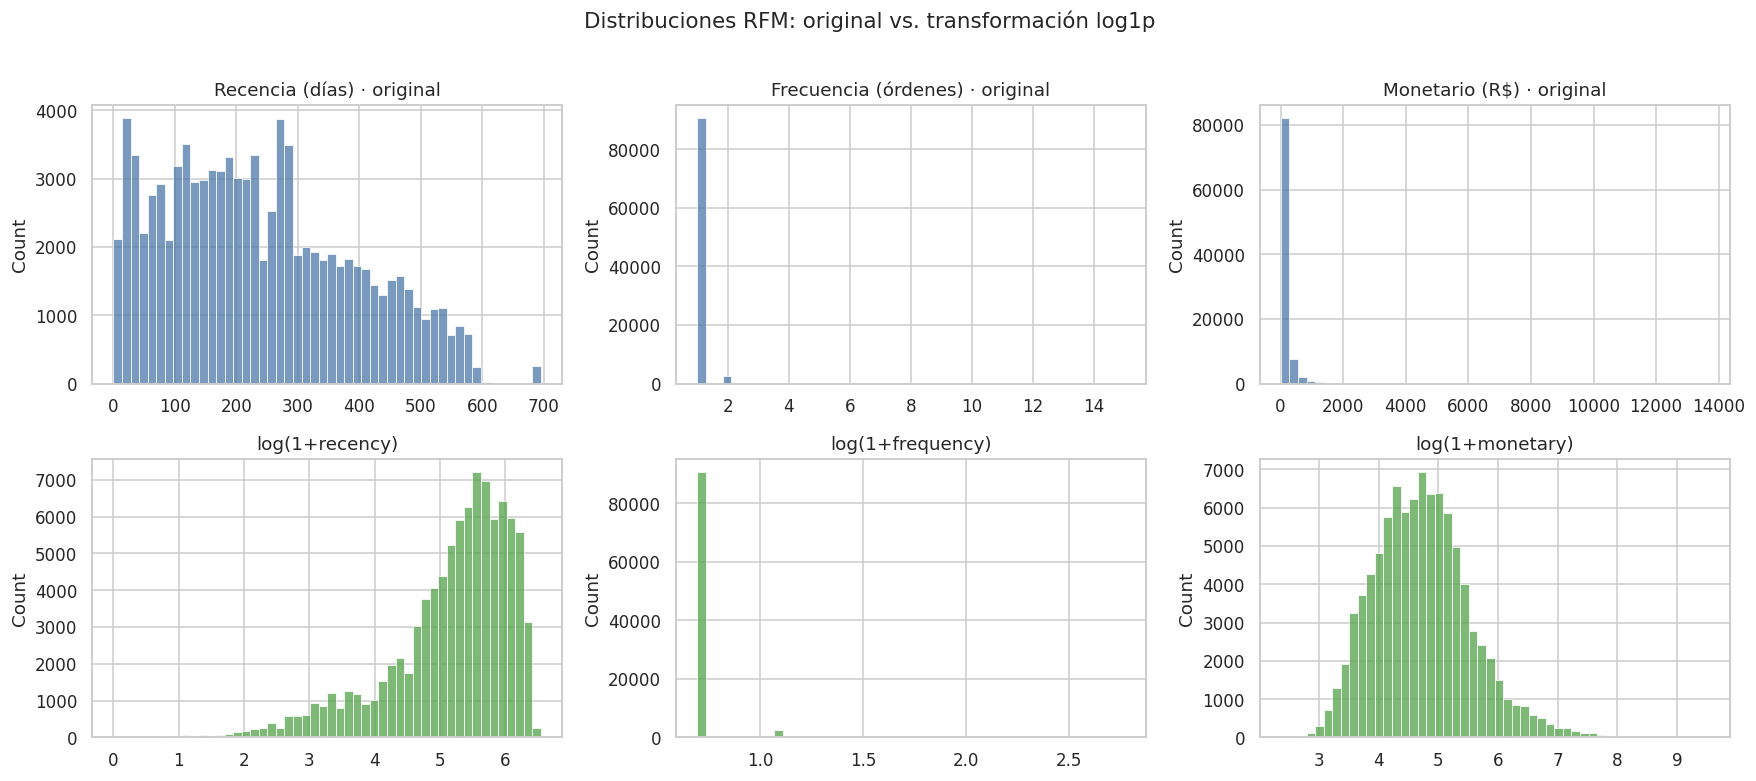

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
names_es = {"recency": "Recencia (días)", "frequency": "Frecuencia (órdenes)", "monetary": "Monetario (R$)"}
for j, col in enumerate(FEATURES):
    sns.histplot(rfm[col], bins=50, ax=axes[0, j], color="#4c78a8")
    axes[0, j].set_title(f"{names_es[col]} · original"); axes[0, j].set_xlabel("")
    sns.histplot(np.log1p(rfm[col]), bins=50, ax=axes[1, j], color="#54a24b")
    axes[1, j].set_title(f"log(1+{col})"); axes[1, j].set_xlabel("")
plt.suptitle("Distribuciones RFM: original vs. transformación log1p", y=1.01, fontsize=14)
plt.tight_layout(); save_fig("03_distribuciones_rfm"); plt.show()
print("Asimetría (skew) original:", rfm[FEATURES].skew().round(2).to_dict())
print("Asimetría tras log1p:    ", np.log1p(rfm[FEATURES]).skew().round(2).to_dict())

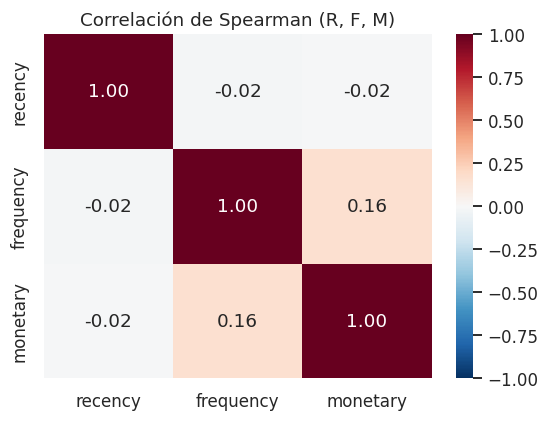

In [10]:
plt.figure(figsize=(5.2, 4))
sns.heatmap(rfm[FEATURES].corr(method="spearman"), annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlación de Spearman (R, F, M)"); plt.tight_layout(); save_fig("04_correlacion_rfm"); plt.show()

Las tres variables están **casi incorrelacionadas** entre sí (|ρ| ≤ 0.16): cada una aporta información distinta, lo cual es bueno para clustering (no hay redundancia).

Sobre la transformación `log1p`: corrige muy bien el **Monetario** (asimetría 9.2 → 0.5) y atenúa la **Frecuencia** (11.1 → 6.5; sigue sesgada porque el 97% vale 1). En la **Recencia**, en cambio, la distribución original ya era casi simétrica (0.45) y el log la vuelve levemente asimétrica a la izquierda (−1.25). Por eso, en la sección 3 hacemos una pequeña **ablación** para decidir si conviene transformarla.

### Variables de perfilamiento
Añadimos (sin usarlas para entrenar) la **reseña promedio** y la **categoría favorita** de cada cliente, para poder *describir* los segmentos después. La tabla también conserva los **tiempos de entrega** (`avg_delivery_days`, `avg_delay_days`), que se usan en el notebook 02 (redes neuronales).

In [11]:
customers_rfm = add_profile_features(rfm, tables, order_table)   # rfm ya incluye cuotas, estado y tiempos de entrega
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
customers_rfm.to_csv(PROCESSED_PATH, index=False)       # la app de Streamlit lee este archivo
print(f"Guardado: {PROCESSED_PATH.relative_to(ROOT)}  ->  {customers_rfm.shape}")
customers_rfm.head()

Guardado: data/processed/customers_rfm.csv  ->  (93357, 10)


,customer_unique_id,frequency,monetary,avg_installments,customer_state,avg_delivery_days,avg_delay_days,recency,avg_review_score,favorite_category
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.900,8.000,SP,6.411,-4.133,111,5.000,bed_bath_table
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.190,1.000,SP,3.286,-4.248,114,4.000,health_beauty
2,0000f46a3911fa3c0805444483337064,1,86.220,8.000,SC,25.732,-1.390,537,3.000,stationery
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.620,4.000,PA,20.037,-11.109,321,4.000,telephony
4,0004aac84e0df4da2b147fca70cf8255,1,196.890,6.000,SP,13.141,-7.035,288,5.000,telephony


## 3. Escalado de variables

Los algoritmos basados en distancia (K-Means, Ward, DBSCAN) son sensibles a la escala: el Monetario (hasta ~13,000) aplastaría a la Frecuencia (1–15). Aplicamos:

1. `log1p` → reduce la asimetría y el efecto de valores extremos.
2. `StandardScaler` → media 0, desviación 1 en cada variable.

In [12]:
df = customers_rfm.copy()
X, scaler = prepare_features(df)
print("Media por variable tras escalar:", X.mean(axis=0).round(6))
print("Desv. estándar tras escalar:    ", X.std(axis=0).round(6))
print("Forma de X:", X.shape)

Media por variable tras escalar: [-0.  0.  0.]
Desv. estándar tras escalar:     [1. 1. 1.]
Forma de X: (93357, 3)


In [13]:
# Ablación: ¿conviene aplicar log1p también a la Recencia? (K-Means, k=4)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

def feats(log_recency):
    A = df[FEATURES].to_numpy(float).copy()
    A[:, 1:] = np.log1p(A[:, 1:])                 # F y M siempre en log
    if log_recency:
        A[:, 0] = np.log1p(A[:, 0])
    return StandardScaler().fit_transform(A)

rows = []
for nombre, flag in [("log1p en R, F y M (el que usamos)", True), ("log1p solo en F y M", False)]:
    Xa = feats(flag)
    lab = KMeans(4, n_init=10, random_state=SEED).fit_predict(Xa)
    rows.append({"transformación": nombre, **evaluate_clustering(Xa, lab)})
pd.DataFrame(rows).set_index("transformación")[["silhouette", "davies_bouldin", "calinski_harabasz"]]

,silhouette,davies_bouldin,calinski_harabasz
transformación,,,
"log1p en R, F y M (el que usamos)",0.397,0.756,"73,976.700"
log1p solo en F y M,0.370,0.785,"70,496.600"


La ablación muestra que **transformar la Recencia con log rinde ligeramente mejor** en las tres métricas (silueta, Davies-Bouldin y Calinski-Harabasz), aunque la diferencia es pequeña. Mantenemos `log1p` en las tres variables por ese resultado empírico y por consistencia metodológica.

> ⚠️ **Detalle técnico:** como el 97% tiene F=1, al estandarizar el valor F=1 queda en ≈ −0.17 mientras que quien compró 2 veces queda en ≈ +5. Los recurrentes serán puntos *muy alejados* del resto en el eje F; K-Means los aislará en su propio cluster.

## 4. Modelado con 3 algoritmos clásicos

### 4.1 K-Means
Parte el espacio en *k* grupos esféricos minimizando la varianza intra-cluster. Para elegir *k* barremos 2–8 y miramos **inercia (codo)**, **silueta**, **Davies-Bouldin** y **Calinski-Harabasz**.

In [14]:
scan_km = scan_k(X, "K-Means", range(2, 9))
scan_km.set_index("k")

,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,inertia
k,,,,,,
2,2,0.000,0.708,0.470,"44,102.300","190,211.900"
3,3,0.000,0.423,0.833,"54,459.300","129,260.200"
4,4,0.000,0.397,0.756,"73,976.700","82,927.200"
5,5,0.000,0.357,0.810,"72,306.900","68,339.600"
6,6,0.000,0.353,0.798,"70,790.900","58,450.500"
7,7,0.000,0.350,0.808,"69,430.000","51,271.900"
8,8,0.000,0.346,0.844,"67,973.600","45,935.000"


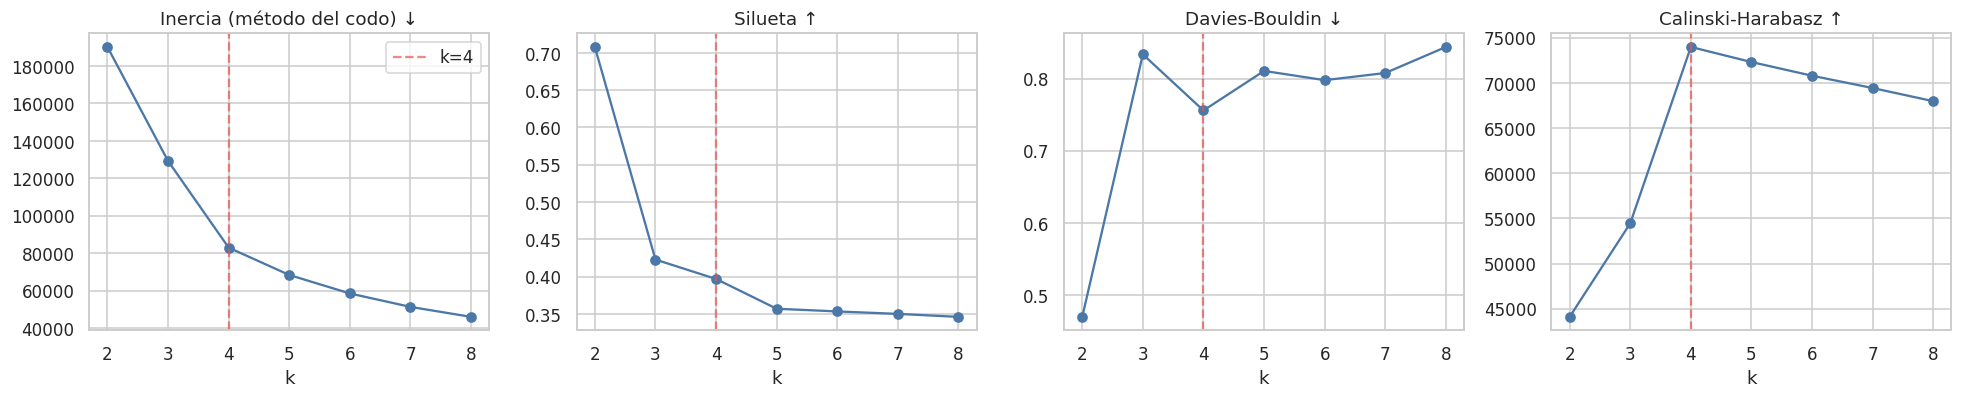

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, (col, title, better) in zip(ax, [("inertia", "Inercia (método del codo)", "↓"),
                                         ("silhouette", "Silueta", "↑"),
                                         ("davies_bouldin", "Davies-Bouldin", "↓"),
                                         ("calinski_harabasz", "Calinski-Harabasz", "↑")]):
    a.plot(scan_km["k"], scan_km[col], marker="o", color="#4c78a8")
    a.axvline(4, color="#e45756", ls="--", alpha=.7, label="k=4")
    a.set_title(f"{title} {better}"); a.set_xlabel("k")
ax[0].legend()
plt.tight_layout(); save_fig("05_kmeans_seleccion_k"); plt.show()

**¿Por qué k = 4?**
- **k = 2** tiene la mejor silueta (≈0.71), pero es una trampa: solo separa a ~2,800 clientes recurrentes (3%) del resto. Ya lo sabíamos por la Frecuencia; no es una segmentación accionable.
- **k = 4** maximiza **Calinski-Harabasz** (≈73,977), tiene el **menor Davies-Bouldin entre los k ≥ 3** (≈0.756) y mantiene una silueta aceptable (≈0.40).
- A partir de k = 5 la inercia mejora poco y la silueta baja: se parte el mismo grupo sin ganar interpretabilidad.

In [16]:
km = fit_model("K-Means", X, k=4)
print("Tamaño de cada cluster:", np.bincount(km.labels).tolist())

Tamaño de cada cluster: [42331, 32199, 2801, 16026]


### 4.2 Clustering jerárquico aglomerativo (Ward)
Construye un árbol de fusiones: cada cliente empieza solo y se unen los grupos que menos aumentan la varianza total (criterio de **Ward**). El dendrograma permite *ver* cuántos grupos naturales hay.

> ⚠️ Necesita la matriz de distancias entre todos los pares (memoria ≈ n²). Con 93k clientes serían ~35 GB, así que se **ajusta sobre una muestra de 8,000** y el resto de clientes se asigna al **centroide más cercano** (coherente con Ward, que minimiza varianza).

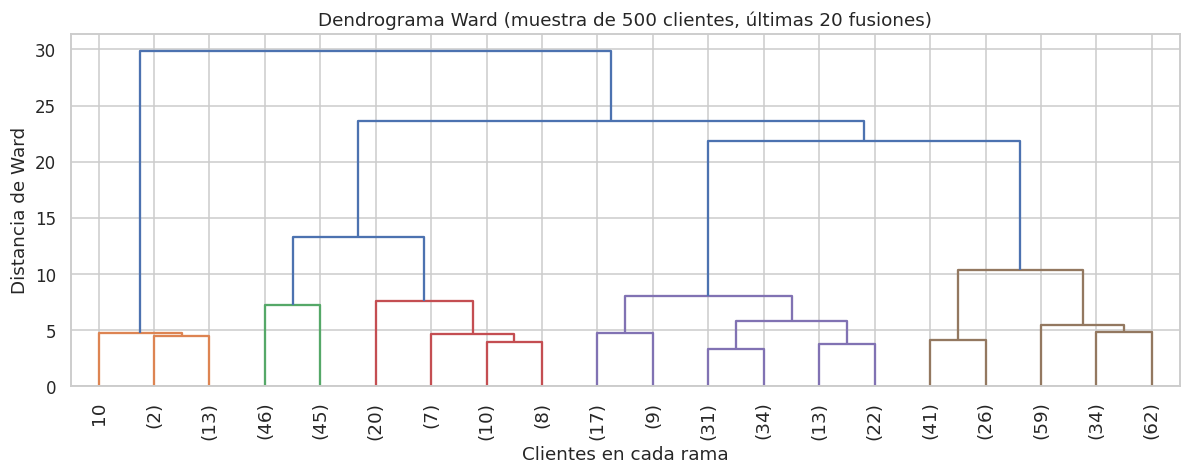

In [17]:
rng = np.random.RandomState(SEED)
idx_d = rng.choice(len(X), 500, replace=False)
Z = linkage(X[idx_d], method="ward")

plt.figure(figsize=(11, 4.5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, show_leaf_counts=True, color_threshold=0.35 * Z[:, 2].max())
plt.title("Dendrograma Ward (muestra de 500 clientes, últimas 20 fusiones)")
plt.xlabel("Clientes en cada rama"); plt.ylabel("Distancia de Ward")
plt.tight_layout(); save_fig("06_dendrograma"); plt.show()

In [18]:
scan_hc = scan_k(X, "Jerárquico (Ward)", range(2, 9))
scan_hc.set_index("k")

,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz
k,,,,,
2,2,0.000,0.708,0.470,"44,102.300"
3,3,0.000,0.419,0.837,"54,352.800"
4,4,0.000,0.373,0.768,"69,729.600"
5,5,0.000,0.347,0.824,"70,772.700"
6,6,0.000,0.343,0.905,"66,733.300"
7,7,0.000,0.339,0.880,"66,395.500"
8,8,0.000,0.336,0.853,"64,950.100"


En Ward, **k = 4** tiene el menor Davies-Bouldin entre los k ≥ 3 (≈0.768) y un Calinski-Harabasz prácticamente empatado con k = 5 (69.7k vs 70.8k); además, usar el mismo k que K-Means permite una **comparación justa entre algoritmos**. En el dendrograma, el tramo vertical más largo sin fusiones (alturas ≈13 a ≈22) corresponde justamente a **4 ramas**, y la primera división aísla un grupo pequeño (el de los clientes recurrentes).

In [19]:
hc = fit_model("Jerárquico (Ward)", X, k=4, sample_size=8000)
print("Tamaño de cada cluster:", np.bincount(hc.labels).tolist())

Tamaño de cada cluster: [43842, 28932, 17782, 2801]


### 4.3 DBSCAN
Agrupa por **densidad**: un punto es *core* si tiene al menos `min_samples` vecinos a distancia ≤ `eps`; los puntos en zonas poco densas se etiquetan como **ruido (-1)**. No requiere fijar *k* y detecta atípicos, pero es sensible a `eps`.

Para elegir `eps` usamos la **curva k-distance**: distancia de cada punto a su vecino número `min_samples`, ordenada. El "codo" sugiere el radio donde se pasa de zona densa a dispersa.

Percentiles de la k-distance (50/75/85/90/95): [0.08  0.134 0.177 0.224 0.341]


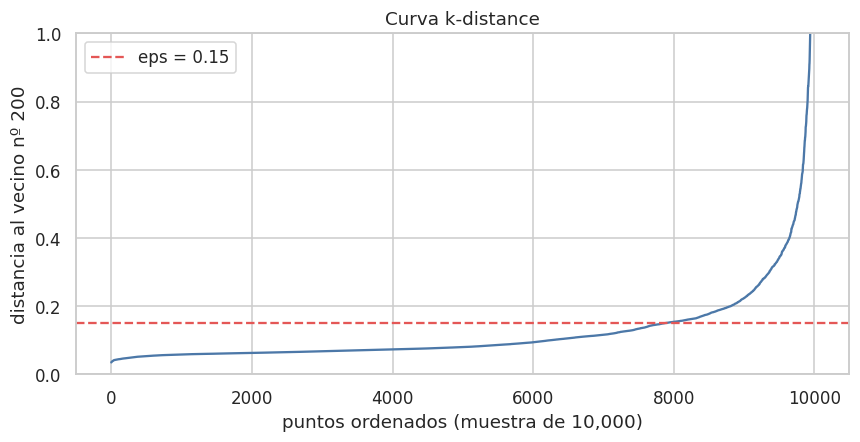

In [20]:
MIN_SAMPLES = 200
rng = np.random.RandomState(SEED)
q = rng.choice(len(X), 10000, replace=False)
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X[q])
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4.2))
plt.plot(kdist, color="#4c78a8"); plt.axhline(0.15, color="#e45756", ls="--", label="eps = 0.15")
plt.ylim(0, 1); plt.xlabel("puntos ordenados (muestra de 10,000)"); plt.ylabel(f"distancia al vecino nº {MIN_SAMPLES}")
plt.title("Curva k-distance"); plt.legend(); plt.tight_layout(); save_fig("07_kdistance"); plt.show()
print("Percentiles de la k-distance (50/75/85/90/95):", np.percentile(kdist, [50, 75, 85, 90, 95]).round(3))

In [21]:
# Pequeña búsqueda de hiperparámetros sobre TODOS los clientes (valores moderados: DBSCAN consume mucha memoria con eps grande)
grid = []
for eps, ms in [(0.10, 100), (0.15, 100), (0.15, 200), (0.20, 300)]:
    m = fit_model("DBSCAN", X, eps=eps, min_samples=ms)
    ev = evaluate_clustering(X, m.labels)
    sizes = sorted(np.bincount(m.labels[m.labels != -1]).tolist(), reverse=True)[:4]
    grid.append({"eps": eps, "min_samples": ms, "clusters": ev["n_clusters"], "% ruido": ev["noise_pct"],
                 "silueta (sin ruido)": ev["silhouette"], "Davies-Bouldin": ev["davies_bouldin"],
                 "tamaños (top 4)": sizes})
pd.DataFrame(grid)

,eps,min_samples,clusters,% ruido,silueta (sin ruido),Davies-Bouldin,tamaños (top 4)
0,0.100,100,10,18.000,0.183,0.715,"[73376, 1374, 446, 432]"
1,0.150,100,1,9.040,NaN,NaN,[84921]
2,0.150,200,3,15.860,0.250,0.489,"[77634, 565, 354]"
3,0.200,300,1,12.840,NaN,NaN,[81366]


**Lectura:** el RFM de Olist es un *continuo* (no hay "islas" de densidad separadas), así que DBSCAN tiende a producir **un núcleo masivo** + microgrupos + ruido. Con `eps=0.10` aparecen 10 grupos pero 18% de ruido; con `eps=0.15, min_samples=100` o `eps=0.20, min_samples=300` todo colapsa en un solo cluster.
Elegimos **eps = 0.15, min_samples = 200**: 3 clusters, ~16% marcado como ruido (clientes atípicos) y un balance razonable. En la curva k-distance, el valor 0.15 cae en la zona donde la curva empieza a dispararse (percentiles 75–90 ≈ 0.13–0.22).

In [22]:
db = fit_model("DBSCAN", X, eps=0.15, min_samples=200)
lab, cnt = np.unique(db.labels, return_counts=True)
print(dict(zip(lab.tolist(), cnt.tolist())), " (-1 = ruido)")

{-1: 14804, 0: 77634, 1: 565, 2: 354}  (-1 = ruido)


## 5. Evaluación cuantitativa de los 3 modelos

In [23]:
fitted = {"K-Means": km, "Jerárquico (Ward)": hc, "DBSCAN": db}
metrics = compare_models(X, fitted)
metrics.to_csv(ROOT / "reports" / "model_comparison.csv")
metrics

,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz
modelo,,,,,
K-Means,4,0.000,0.397,0.756,"73,976.700"
Jerárquico (Ward),4,0.000,0.373,0.768,"69,729.600"
DBSCAN,3,15.860,0.250,0.489,"2,137.600"


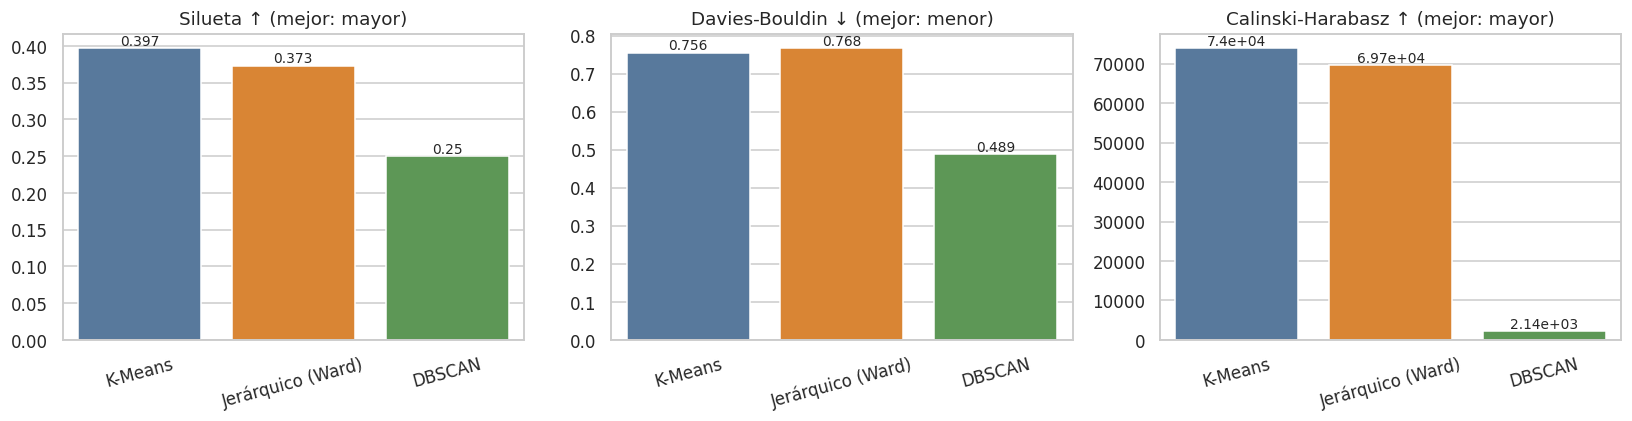

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (col, title) in zip(ax, [("silhouette", "Silueta ↑ (mejor: mayor)"),
                                ("davies_bouldin", "Davies-Bouldin ↓ (mejor: menor)"),
                                ("calinski_harabasz", "Calinski-Harabasz ↑ (mejor: mayor)")]):
    sns.barplot(x=metrics.index, y=metrics[col], hue=metrics.index, ax=a, palette=["#4c78a8", "#f58518", "#54a24b"], legend=False)
    a.set_title(title); a.set_xlabel(""); a.set_ylabel(""); a.tick_params(axis="x", rotation=15)
    for p in a.patches:
        a.annotate(f"{p.get_height():,.3g}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)
plt.tight_layout(); save_fig("08_comparacion_metricas"); plt.show()

### Interpretación (en lenguaje de negocio)

| Métrica | Qué mide | K-Means | Jerárquico | DBSCAN |
|---|---|---|---|---|
| **Silueta** (−1 a 1) | Qué tan bien "encaja" cada cliente en su grupo vs. el vecino más cercano | **0.397** | 0.373 | 0.250 |
| **Davies-Bouldin** (0 = ideal) | Solapamiento entre grupos | 0.756 | 0.768 | 0.489* |
| **Calinski-Harabasz** | Separación entre grupos / compacidad interna | **73,977** | 69,730 | 2,138* |

- **K-Means es el mejor modelo global:** mayor silueta (separación aceptable, 0.25–0.5) y mayor Calinski-Harabasz, además de ser el más simple de explicar y de poner en producción (basta con asignar al centroide más cercano).
- **Ward queda muy cerca** (diferencias de ~6% o menos): ambos encuentran la misma estructura. Que dos algoritmos distintos coincidan *refuerza* la validez de los segmentos.
- **DBSCAN** obtiene el mejor Davies-Bouldin, pero **no es comparable directamente** (*): las métricas se calculan **excluyendo el ~16% de ruido** y con un núcleo masivo que contiene 83% de los clientes. Su valor real es otro: **detectar clientes atípicos** (valores extremos) más que segmentar la base.
- Silueta ≈ 0.40 significa que los segmentos tienen **frontera difusa**: es lo esperable en datos de comportamiento, donde los clientes forman un continuo y no grupos "naturales" perfectos.

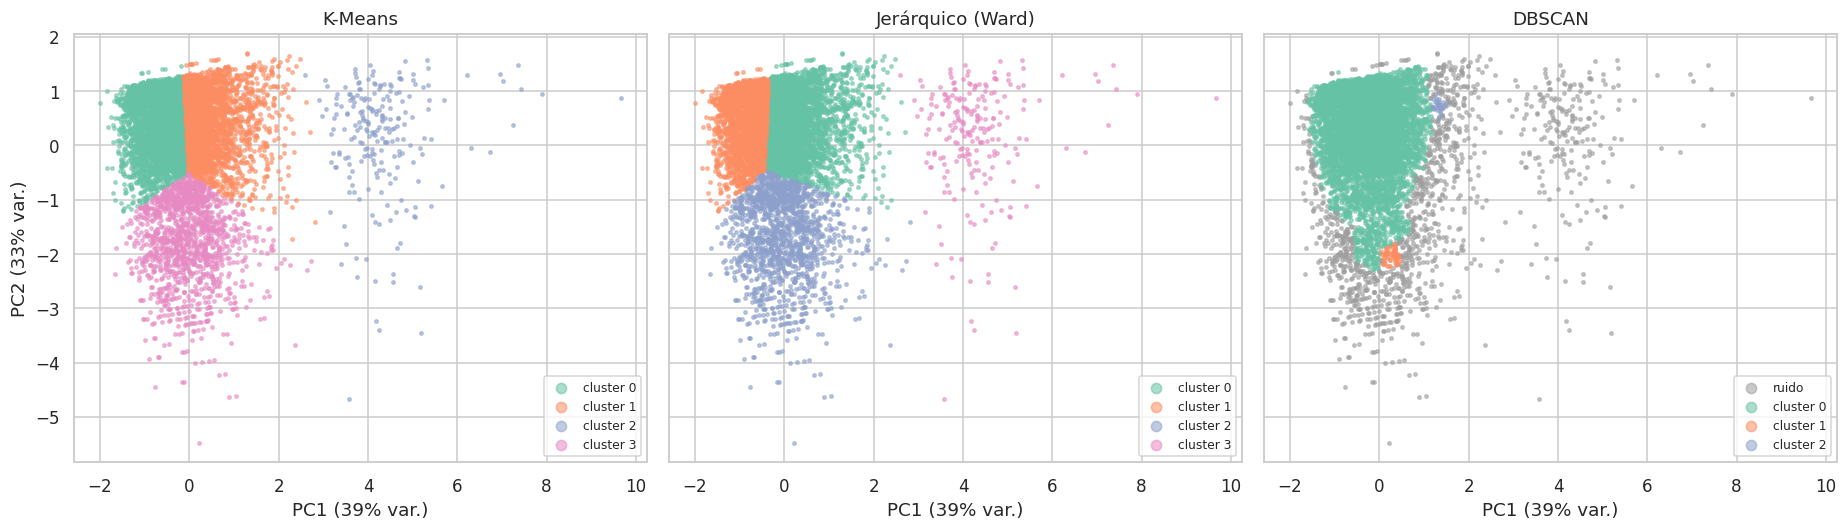

In [25]:
# Proyección 2D con PCA para "ver" qué está agrupando cada algoritmo (misma muestra en los 3 paneles)
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
samp = np.random.RandomState(SEED).choice(len(X), 8000, replace=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for a, (name, m) in zip(ax, fitted.items()):
    lab = m.labels[samp]
    for c in sorted(set(lab)):
        sel = lab == c
        a.scatter(P[samp][sel, 0], P[samp][sel, 1], s=5, alpha=.55,
                  color="#9e9e9e" if c == -1 else sns.color_palette("Set2")[c % 8],
                  label="ruido" if c == -1 else f"cluster {c}")
    a.set_title(name); a.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f}% var.)")
    a.legend(markerscale=3, fontsize=8)
ax[0].set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f}% var.)")
plt.tight_layout(); save_fig("09_pca_modelos"); plt.show()

## 6. Perfilamiento de segmentos (modelo elegido: K-Means, k = 4)

Traducimos los clusters a lenguaje de negocio con el perfil promedio en **unidades originales**. Los nombres se generan con reglas simples (recencia vs. mediana global, monetario vs. percentil 75, frecuencia ≥ 1.5).

In [26]:
df["cluster"] = km.labels
prof = profile_segments(df, km.labels)
seg_names = name_segments(prof, df)
prof["nombre"] = prof.index.map(seg_names)
df["segmento"] = df["cluster"].map(seg_names)
prof[["nombre", "clientes", "pct_clientes", "recencia_media", "frecuencia_media", "monetario_medio",
      "monetario_mediano", "pct_ingresos", "review_promedio"]]

,nombre,clientes,pct_clientes,recencia_media,frecuencia_media,monetario_medio,monetario_mediano,pct_ingresos,review_promedio
segment,,,,,,,,,
0,0 · Inactivos de ticket bajo (dormidos),42331,45.340,286.700,1.000,68.240,65.920,18.730,4.170
1,1 · Inactivos de alto valor (en riesgo),32199,34.490,271.870,1.000,295.920,199.440,61.780,4.050
2,2 · Recurrentes,2801,3.000,219.810,2.110,308.590,225.550,5.600,4.210
3,3 · Recientes de ticket bajo,16026,17.170,41.420,1.000,133.610,103.680,13.880,4.320


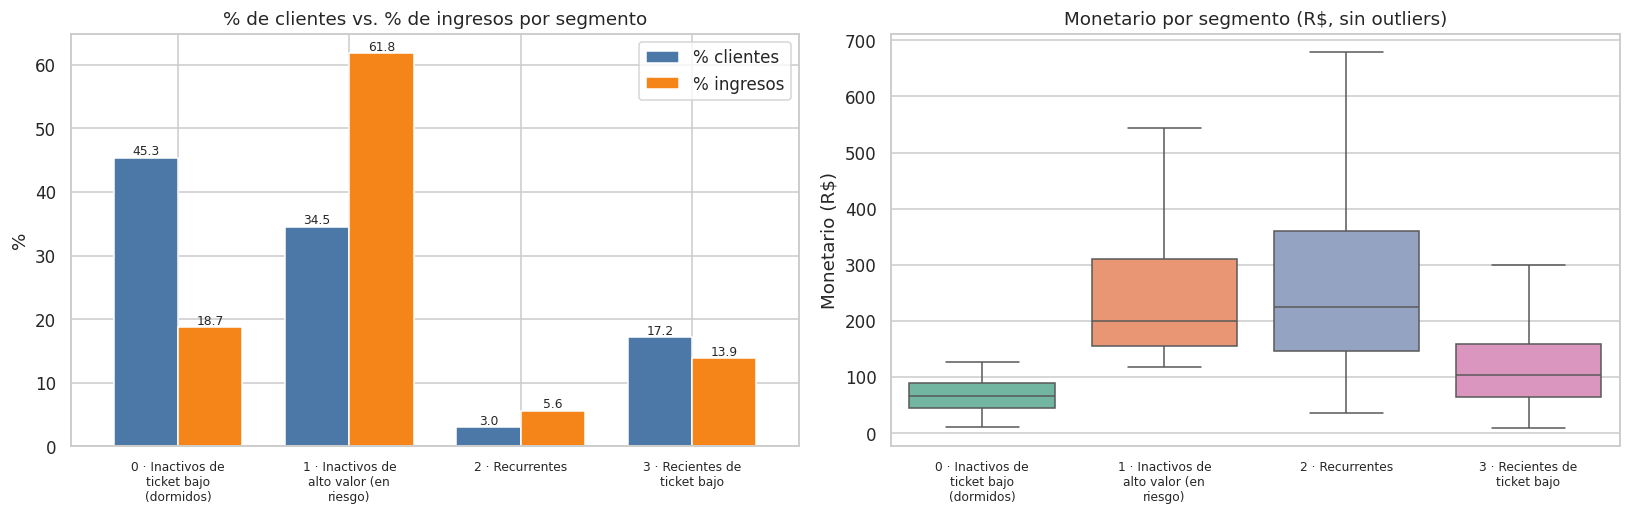

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
share = prof.set_index("nombre")[["pct_clientes", "pct_ingresos"]]
share.plot(kind="bar", ax=ax[0], color=["#4c78a8", "#f58518"], width=.75)
ax[0].set_title("% de clientes vs. % de ingresos por segmento"); ax[0].set_xlabel(""); ax[0].set_ylabel("%")
ax[0].set_xticklabels([textwrap.fill(t.get_text(), 16) for t in ax[0].get_xticklabels()], rotation=0, fontsize=8)
ax[0].legend(["% clientes", "% ingresos"])
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.1f", fontsize=8)

order = prof["nombre"].tolist()
sns.boxplot(data=df, x="segmento", y="monetary", order=order, hue="segmento", hue_order=order, ax=ax[1], palette="Set2", showfliers=False, legend=False)
ax[1].set_title("Monetario por segmento (R$, sin outliers)"); ax[1].set_xlabel(""); ax[1].set_ylabel("Monetario (R$)")
ax[1].set_xticklabels([textwrap.fill(t.get_text(), 16) for t in ax[1].get_xticklabels()], rotation=0, fontsize=8)
plt.tight_layout(); save_fig("10_perfil_segmentos"); plt.show()

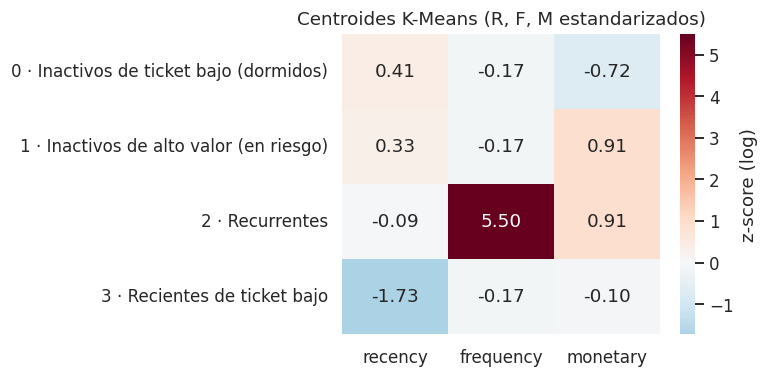

In [28]:
# Heatmap de centroides: ¿en qué se diferencia cada segmento? (valores estandarizados: >0 = por encima del promedio global)
cent = pd.DataFrame(X, columns=FEATURES).groupby(km.labels).mean()
cent.index = [seg_names[i] for i in cent.index]
plt.figure(figsize=(7, 3.6))
sns.heatmap(cent, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score (log)"})
plt.title("Centroides K-Means (R, F, M estandarizados)"); plt.tight_layout(); save_fig("11_centroides"); plt.show()

In [29]:
# Perfil complementario: categorías favoritas, reseña y estado dominante por segmento
rows = []
for seg, g in df.groupby("segmento"):
    top = g["favorite_category"].value_counts(normalize=True).head(3)
    rows.append({"segmento": seg,
                 "top 3 categorías (% de clientes)": ", ".join(f"{c} ({100*p:.0f}%)" for c, p in top.items()),
                 "estado dominante": g["customer_state"].value_counts(normalize=True).head(1).index[0],
                 "% en SP": round(100 * (g["customer_state"] == "SP").mean(), 1),
                 "reseña media": round(g["avg_review_score"].mean(), 2)})
pd.DataFrame(rows).set_index("segmento")

,top 3 categorías (% de clientes),estado dominante,% en SP,reseña media
segmento,,,,
0 · Inactivos de ticket bajo (dormidos),"bed_bath_table (10%), health_beauty (9%), spor...",SP,44.400,4.170
1 · Inactivos de alto valor (en riesgo),"bed_bath_table (9%), watches_gifts (8%), sport...",SP,36.100,4.050
2 · Recurrentes,"bed_bath_table (18%), furniture_decor (10%), h...",SP,43.700,4.210
3 · Recientes de ticket bajo,"health_beauty (12%), bed_bath_table (10%), hou...",SP,46.800,4.320


### 🧠 Hallazgos de negocio

1. **Inactivos de alto valor (en riesgo)** — ~34% de los clientes pero **~62% de los ingresos**. Es el segmento más importante: compraron un ticket alto (~R$ 296 en promedio) hace ~9 meses y no volvieron. *Acción:* campañas de reconquista personalizadas.
2. **Inactivos de ticket bajo (dormidos)** — el grupo más grande (~45%) pero solo ~19% de los ingresos (ticket ~R$ 68). *Acción:* reactivación automatizada de bajo costo.
3. **Recientes de ticket bajo** — ~17% de clientes, compraron hace ~41 días y mejor reseña promedio (~4.3). *Acción:* aumentar ticket con bundles y recomendaciones.
4. **Recurrentes** — solo ~3% (≈2,800 clientes, ~2.1 órdenes en promedio) pero son la prueba de que la recompra es posible; *Acción:* programa de fidelización.

> Los **ids** de cluster pueden variar según la versión de scikit-learn; por eso siempre referimos los segmentos por su **nombre**.

**Acciones sugeridas (generadas por `recommend_action`):**

In [30]:
for seg in sorted(seg_names):
    print(f"• {seg_names[seg]}\n    → {recommend_action(seg_names[seg])}")

• 0 · Inactivos de ticket bajo (dormidos)
    → Reactivación de bajo costo: email automatizado y promociones por categoría favorita; no sobreinvertir.
• 1 · Inactivos de alto valor (en riesgo)
    → Reactivar con prioridad: campañas personalizadas de reconquista y cupones de recompra (concentran gran parte de los ingresos).
• 2 · Recurrentes
    → Cuidar y recompensar: son la minoría que ya recompra; programa de puntos y comunicación frecuente.
• 3 · Recientes de ticket bajo
    → Hacer crecer el ticket: bundles, envío gratis sobre un monto y recomendaciones de productos.


## 7. Persistencia de artefactos para el despliegue

In [31]:
MODELS_DIR = ROOT / "models"; MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(scaler, MODELS_DIR / "scaler.joblib")
for slug, fm in {"kmeans": km, "hierarchical": hc, "dbscan": db}.items():
    joblib.dump(fm.artifact, MODELS_DIR / f"{slug}.joblib")
prof.to_csv(ROOT / "reports" / "kmeans_segment_profile.csv")
print("Artefactos guardados en models/:", sorted(p.name for p in MODELS_DIR.glob("*.joblib")))
print("\nPara lanzar la app:  streamlit run app.py")

Artefactos guardados en models/: ['dbscan.joblib', 'hierarchical.joblib', 'kmeans.joblib', 'neural_preprocessing.joblib', 'scaler.joblib']

Para lanzar la app:  streamlit run app.py


## 8. Conclusiones, limitaciones y trabajo futuro

**Conclusiones**
- Integramos 7 tablas de Olist para construir un RFM sobre **93,357 clientes reales** (`customer_unique_id`), tras filtrar órdenes entregadas con pago válido.
- Comparamos **K-Means, Ward y DBSCAN** con silueta, Davies-Bouldin y Calinski-Harabasz. **K-Means (k=4)** fue el mejor equilibrio entre métricas, interpretabilidad y facilidad de despliegue.
- La segmentación revela una oportunidad clara: los **clientes inactivos de alto valor** concentran ~62% del ingreso.

**Limitaciones**
- ~97% de los clientes compró una sola vez: la Frecuencia aporta poca variabilidad y los clusters se explican sobre todo por Recencia y Monetario.
- Silueta ≈ 0.40 indica fronteras difusas entre segmentos (los clientes forman un continuo).
- Ward y DBSCAN se ajustan con muestras (por memoria); las asignaciones del resto se hacen por proximidad.
- La Recencia depende de la fecha de corte del dataset (oct-2018); en un caso real se recalcularía periódicamente.

**Trabajo futuro**
- Añadir variables (categoría, método de pago, tiempo de entrega, reseñas) al espacio de clustering; probar Gaussian Mixture.
- Usar `olist_geolocation_dataset.csv` para análisis geográfico de los segmentos.
- Validar la estabilidad de los segmentos en el tiempo (bootstrapping / ventanas temporales).

**Referencia:** Olist. (2018). *Brazilian E-Commerce Public Dataset by Olist* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce